# Prediksi Curah Hujan Mingguan dengan LSTM
Dataset: `data/weather.csv` (data mingguan, 307 stasiun cuaca AS, 2016-01-03 s.d. 2017-01-01).

**Catatan desain:** tiap stasiun hanya punya 53 titik mingguan, terlalu sedikit untuk satu model per stasiun. Maka satu model LSTM dilatih dari jendela (window) semua stasiun, dengan pembagian train/test berdasarkan **waktu** (bukan acak) agar tidak terjadi kebocoran data.

In [1]:
import os, json, random
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Input
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
os.makedirs('../model', exist_ok=True)
pd.set_option('display.width', 140)

I0000 00:00:1793431222.692042     170 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793431222.748827     170 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793431224.702955     170 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## 1. Eksplorasi Data (EDA)

In [2]:
df = pd.read_csv('../data/weather.csv')
df = df.rename(columns={
    'Data.Precipitation':'precip', 'Date.Full':'date',
    'Station.City':'city', 'Station.Code':'code', 'Station.State':'state',
    'Data.Temperature.Avg Temp':'temp_avg', 'Data.Temperature.Max Temp':'temp_max',
    'Data.Temperature.Min Temp':'temp_min', 'Data.Wind.Speed':'wind_speed',
    'Data.Wind.Direction':'wind_dir'})
df['date'] = pd.to_datetime(df['date'])
df = df[['date','code','city','state','precip','temp_avg','temp_max','temp_min','wind_speed','wind_dir']]
print(df.shape); print(df['date'].min(), '->', df['date'].max(), '| minggu unik:', df['date'].nunique())
print('stasiun:', df['code'].nunique())
df.head()

(16743, 10)
2016-01-03 00:00:00 -> 2017-01-01 00:00:00 | minggu unik: 53
stasiun: 318


,date,code,city,state,precip,temp_avg,temp_max,temp_min,wind_speed,wind_dir
0,2016-01-03,BHM,Birmingham,Alabama,0.00,39,46,32,4.33,33
1,2016-01-03,HSV,Huntsville,Alabama,0.00,39,47,31,3.86,32
2,2016-01-03,MOB,Mobile,Alabama,0.16,46,51,41,9.73,35
3,2016-01-03,MGM,Montgomery,Alabama,0.00,45,52,38,6.86,32
4,2016-01-03,ANC,Anchorage,Alaska,0.01,34,38,29,7.80,19


In [3]:
print(df.isna().sum())
print('duplikat (date, code):', df.duplicated(['date','code']).sum())
print(df[['precip','temp_avg','temp_max','temp_min','wind_speed','wind_dir']].describe().T)
print('proporsi minggu tanpa hujan:', (df['precip']==0).mean().round(3))

date          0
code          0
city          0
state         0
precip        0
temp_avg      0
temp_max      0
temp_min      0
wind_speed    0
wind_dir      0
dtype: int64
duplikat (date, code): 0
              count       mean        std   min    25%    50%    75%     max
precip      16743.0   0.579090   0.988057   0.0   0.00   0.19   0.75   20.89
temp_avg    16743.0  56.089112  18.798295 -27.0  44.00  58.00  71.00  100.00
temp_max    16743.0  66.042406  19.787954 -19.0  53.00  68.00  82.00  111.00
temp_min    16743.0  45.642716  18.559263 -35.0  33.00  47.00  60.00   88.00
wind_speed  16743.0   6.329820   3.494785   0.0   4.04   5.94   8.08   61.10
wind_dir    16743.0  18.791316   6.461527   0.0  15.00  19.00  23.00   36.00
proporsi minggu tanpa hujan: 0.258


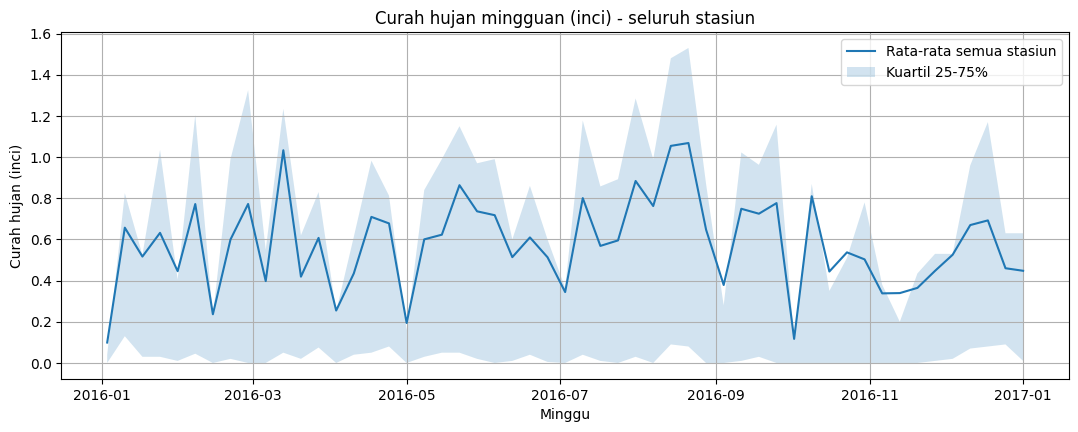

In [4]:
# Plot waktu: rata-rata nasional + rentang antar-kuartil antar stasiun
g = df.groupby('date')['precip']
fig, ax = plt.subplots(figsize=(13,4.5))
ax.plot(g.mean().index, g.mean().values, color='tab:blue', label='Rata-rata semua stasiun')
ax.fill_between(g.mean().index, g.quantile(.25), g.quantile(.75), alpha=.2, label='Kuartil 25-75%')
ax.set_title('Curah hujan mingguan (inci) - seluruh stasiun'); ax.set_xlabel('Minggu'); ax.set_ylabel('Curah hujan (inci)')
ax.grid(True); ax.legend(); plt.show()

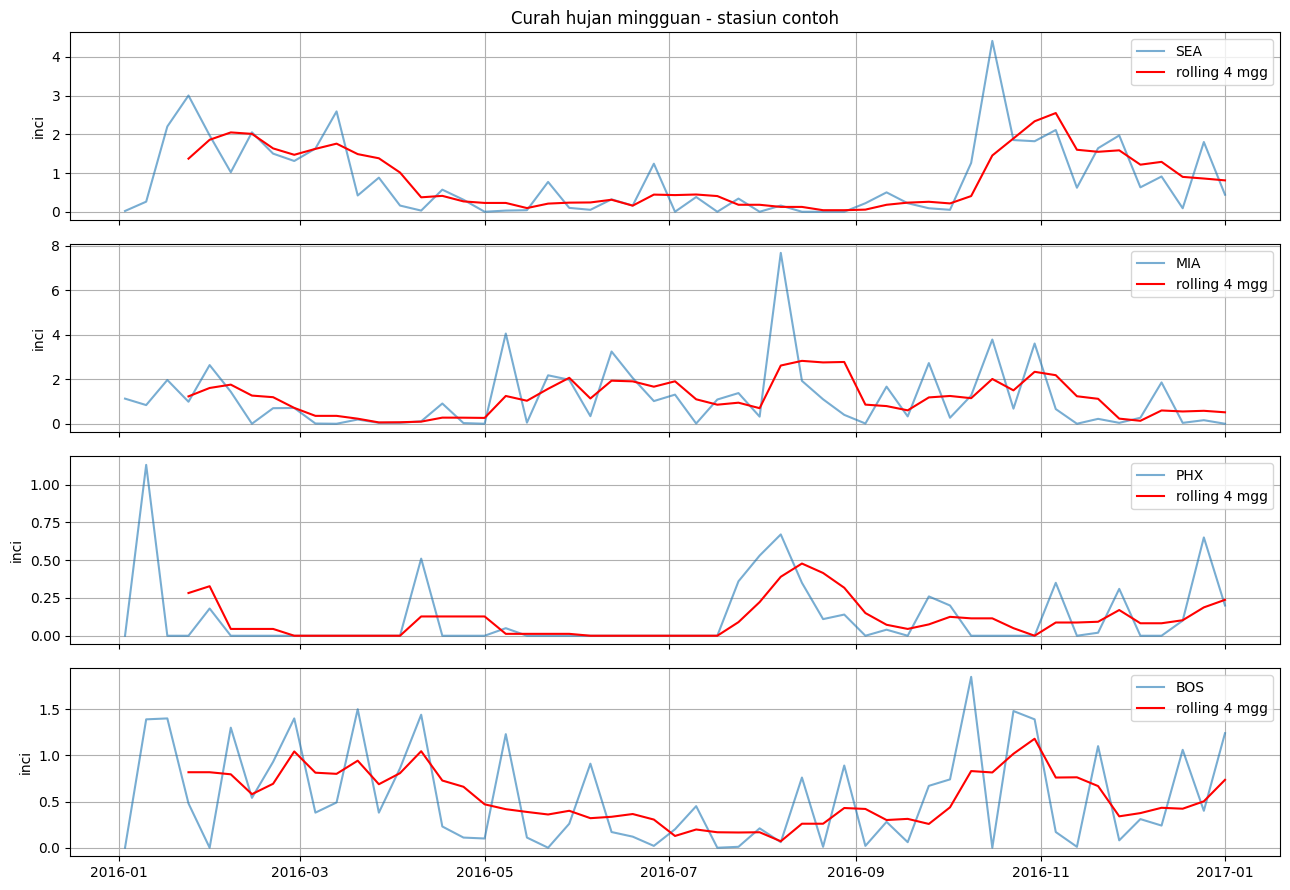

In [5]:
# Plot waktu beberapa stasiun contoh + tren (rolling mean 4 minggu)
contoh = ['SEA','MIA','PHX','BOS']
fig, axes = plt.subplots(len(contoh),1, figsize=(13,9), sharex=True)
for ax, c in zip(axes, contoh):
    s = df[df.code==c].set_index('date')['precip']
    ax.plot(s.index, s.values, alpha=.6, label=c)
    ax.plot(s.index, s.rolling(4).mean(), color='red', label='rolling 4 mgg')
    ax.set_ylabel('inci'); ax.legend(loc='upper right'); ax.grid(True)
axes[0].set_title('Curah hujan mingguan - stasiun contoh'); plt.tight_layout(); plt.show()

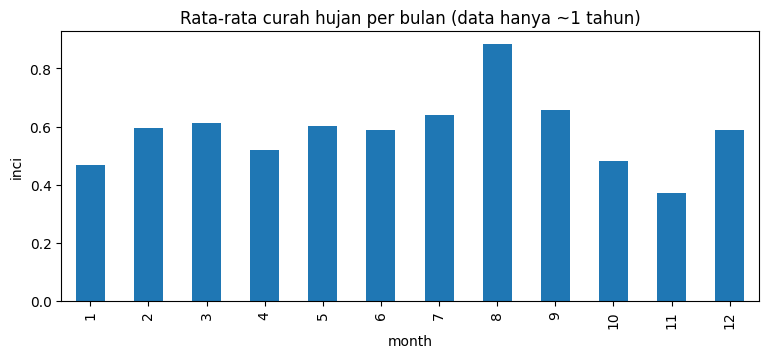

            precip  temp_avg  temp_max  temp_min  wind_speed  wind_dir
precip        1.00      0.12      0.07      0.17       -0.00     -0.11
temp_avg      0.12      1.00      0.98      0.98       -0.16     -0.15
temp_max      0.07      0.98      1.00      0.92       -0.20     -0.10
temp_min      0.17      0.98      0.92      1.00       -0.12     -0.20
wind_speed   -0.00     -0.16     -0.20     -0.12        1.00      0.06
wind_dir     -0.11     -0.15     -0.10     -0.20        0.06      1.00


In [6]:
# Musiman: rata-rata per bulan, dan korelasi antar variabel
df['month'] = df['date'].dt.month
df.groupby('month')['precip'].mean().plot(kind='bar', figsize=(9,3.5), title='Rata-rata curah hujan per bulan (data hanya ~1 tahun)')
plt.ylabel('inci'); plt.show()
print(df[['precip','temp_avg','temp_max','temp_min','wind_speed','wind_dir']].corr().round(2))

> **Catatan:** data hanya mencakup ~1 tahun, sehingga pola musiman tahunan tidak dapat divalidasi penuh. Hujan mingguan juga sangat *noisy* dan *right-skewed*, jadi RMSE model perlu dibandingkan dengan baseline.

## 2. Pembersihan Data

In [7]:
# Hapus duplikat, urutkan, pastikan tiap stasiun punya deret waktu lengkap
df = df.drop_duplicates(['date','code']).sort_values(['code','date']).reset_index(drop=True)
df['precip'] = df['precip'].clip(lower=0)

all_weeks = pd.DatetimeIndex(sorted(df['date'].unique()))
cnt = df.groupby('code')['date'].nunique()
print('minggu total:', len(all_weeks), '| stasiun lengkap:', (cnt==len(all_weeks)).sum(), '/', len(cnt))

# Pertahankan hanya stasiun dengan deret lengkap (tanpa celah), agar window valid
lengkap = cnt[cnt==len(all_weeks)].index
df = df[df.code.isin(lengkap)].copy()
print('stasiun dipakai:', df.code.nunique())

# Outlier: winsorize ringan pada kecepatan angin & hujan (persentil 99.9)
for c in ['precip','wind_speed']:
    df[c] = df[c].clip(upper=df[c].quantile(.999))

# Fitur musiman (siklus minggu dalam tahun)
woy = df['date'].dt.isocalendar().week.astype(int)
df['week_sin'] = np.sin(2*np.pi*woy/52); df['week_cos'] = np.cos(2*np.pi*woy/52)

minggu total: 53 | stasiun lengkap: 308 / 318
stasiun dipakai: 308


## 3. Scaling & Windowing
Target = `precip` minggu berikutnya. Split berdasarkan waktu: 80% minggu awal = latih, 20% minggu akhir = uji. Scaler **hanya di-fit pada data latih**.

In [8]:
FEATURES = ['precip','temp_avg','temp_max','temp_min','wind_speed','wind_dir','week_sin','week_cos']
TARGET = 'precip'
TIMESTEPS = 4          # 4 minggu terakhir -> prediksi minggu ke-5
TARGET_IDX = FEATURES.index(TARGET)

weeks = np.array(sorted(df['date'].unique()))
split_idx = int(len(weeks)*0.8)
split_date = weeks[split_idx]
print('minggu latih:', split_idx, '| minggu uji:', len(weeks)-split_idx, '| split di:', pd.Timestamp(split_date).date())

train_rows = df[df['date'] < split_date]
scaler = MinMaxScaler(feature_range=(0,1)).fit(train_rows[FEATURES])

def make_windows(frame, start, end):
    """Buat (X,y) dengan target pada indeks minggu t, t di [start, end)."""
    X, y, meta = [], [], []
    for code, g in frame.groupby('code'):
        g = g.sort_values('date')
        arr = scaler.transform(g[FEATURES])
        for t in range(max(TIMESTEPS, start), end):
            X.append(arr[t-TIMESTEPS:t, :])
            y.append(arr[t, TARGET_IDX])
            meta.append((code, g['date'].iloc[t]))
    return np.array(X, dtype='float32'), np.array(y, dtype='float32'), meta

# Target di minggu < split => latih; target di minggu >= split => uji.
# Window uji boleh memakai minggu terakhir periode latih sebagai input (hanya fitur masa lalu, tidak bocor).
X_train, y_train, meta_train = make_windows(df, 0, split_idx)
X_test,  y_test,  meta_test  = make_windows(df, split_idx, len(weeks))
print('X_train', X_train.shape, '| X_test', X_test.shape)  # (samples, timesteps, features)

minggu latih: 42 | minggu uji: 11 | split di: 2016-10-23


X_train (11704, 4, 8) | X_test (3388, 4, 8)


## 4. Model LSTM

In [9]:
model = Sequential([
    Input(shape=(TIMESTEPS, len(FEATURES))),
    LSTM(64, return_sequences=True),
    Dropout(0.2),
    LSTM(32, return_sequences=False),
    Dropout(0.2),
    Dense(16, activation='relu'),
    Dense(1)
])
model.compile(optimizer='adam', loss='mean_squared_error')
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 4, 64)          │        18,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 4, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 31,649 (123.63 KB)

 Trainable params: 31,649 (123.63 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/60


156/156 - 5s - 33ms/step - loss: 0.0124 - val_loss: 0.0145


Epoch 2/60


156/156 - 2s - 14ms/step - loss: 0.0119 - val_loss: 0.0141


Epoch 3/60


156/156 - 2s - 14ms/step - loss: 0.0117 - val_loss: 0.0140


... (98 outputs left out)

Epoch 53/60


156/156 - 2s - 16ms/step - loss: 0.0109 - val_loss: 0.0132


Epoch 54/60


156/156 - 3s - 17ms/step - loss: 0.0109 - val_loss: 0.0131


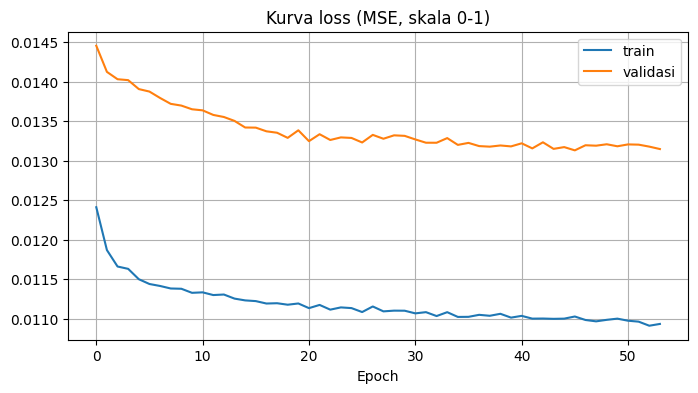

In [10]:
es = EarlyStopping(monitor='val_loss', patience=8, restore_best_weights=True)
history = model.fit(X_train, y_train, epochs=60, batch_size=64,
                    validation_split=0.15, shuffle=True, callbacks=[es], verbose=2)

plt.figure(figsize=(8,4))
plt.plot(history.history['loss'], label='train'); plt.plot(history.history['val_loss'], label='validasi')
plt.title('Kurva loss (MSE, skala 0-1)'); plt.xlabel('Epoch'); plt.legend(); plt.grid(True); plt.show()

> `validation_split` mengambil 15% *terakhir* dari data latih (Keras memotong sebelum mengacak), jadi validasi berada di periode yang lebih baru. Data uji tidak dipakai untuk early stopping.

## 5. Evaluasi

In [11]:
def inv_target(v):
    tmp = np.zeros((len(v), len(FEATURES))); tmp[:, TARGET_IDX] = np.ravel(v)
    return scaler.inverse_transform(tmp)[:, TARGET_IDX]

pred = np.clip(inv_target(model.predict(X_test, verbose=0)), 0, None)
actual = inv_target(y_test)

# Baseline: persistence (hujan minggu lalu) dan rata-rata data latih
persist = inv_target(X_test[:, -1, TARGET_IDX])
mean_base = np.full_like(actual, train_rows['precip'].mean())

def report(name, p):
    return {'model': name, 'RMSE': round(float(np.sqrt(mean_squared_error(actual, p))),4),
            'MAE': round(float(mean_absolute_error(actual, p)),4)}
res = pd.DataFrame([report('LSTM', pred), report('Persistence (minggu lalu)', persist), report('Rata-rata latih', mean_base)])
print(res.to_string(index=False))
print('Satuan: inci/minggu | rata-rata hujan data uji:', actual.mean().round(3))

                    model   RMSE    MAE
                     LSTM 0.7848 0.4577
Persistence (minggu lalu) 0.9964 0.5625
          Rata-rata latih 0.8377 0.5810
Satuan: inci/minggu | rata-rata hujan data uji: 0.489


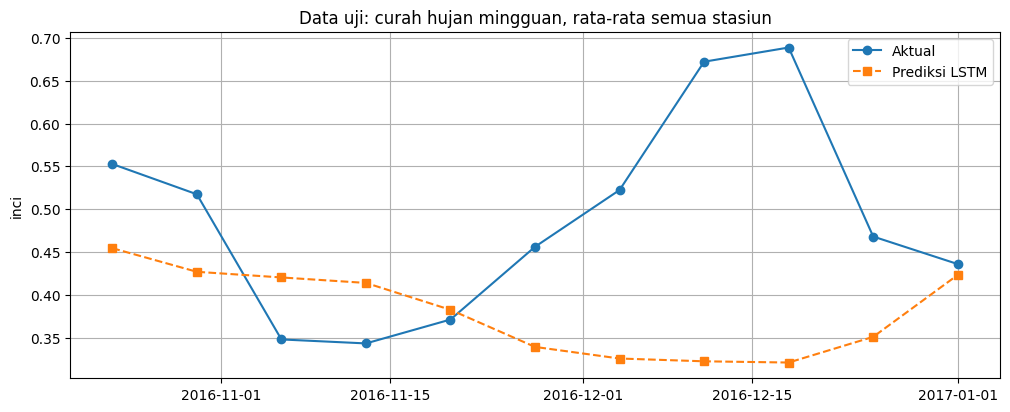

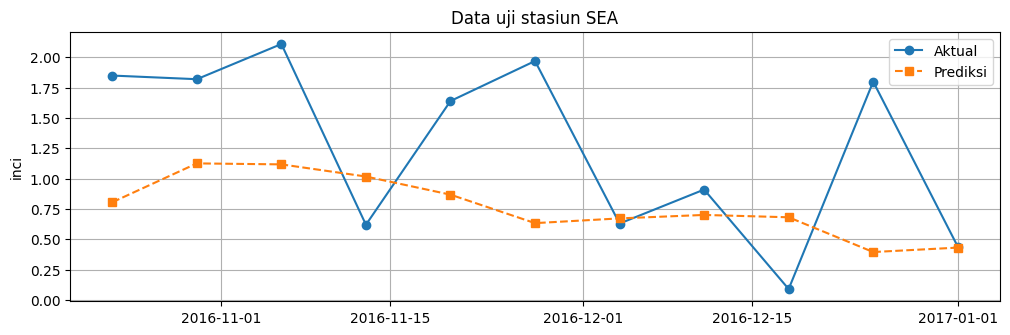

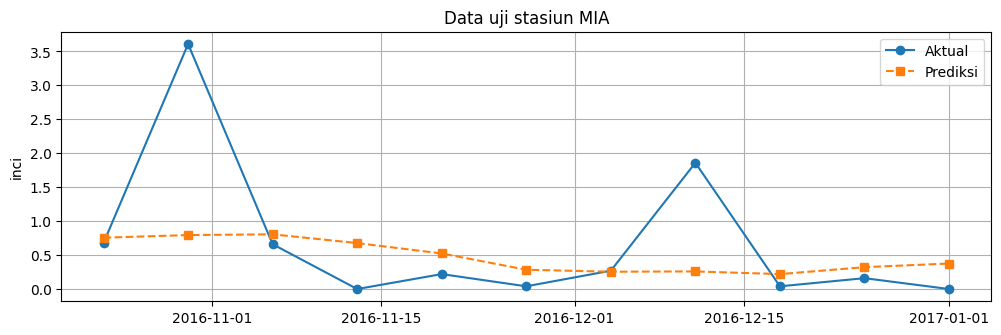

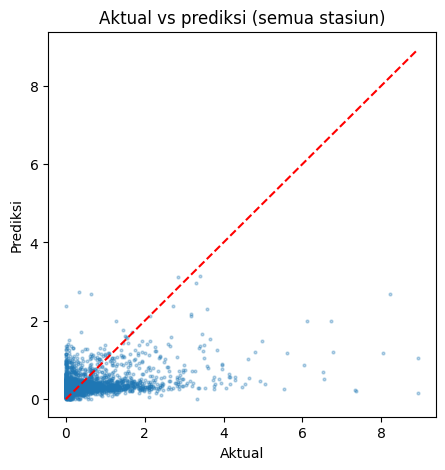

In [12]:
# Aktual vs prediksi pada data uji
ev = pd.DataFrame(meta_test, columns=['code','date']); ev['actual']=actual; ev['pred']=pred
w = ev.groupby('date')[['actual','pred']].mean()
plt.figure(figsize=(12,4.5))
plt.plot(w.index, w['actual'], 'o-', label='Aktual'); plt.plot(w.index, w['pred'], 's--', label='Prediksi LSTM')
plt.title('Data uji: curah hujan mingguan, rata-rata semua stasiun'); plt.ylabel('inci'); plt.grid(True); plt.legend(); plt.show()

for code in ['SEA','MIA']:
    s = ev[ev.code==code].set_index('date')
    plt.figure(figsize=(12,3.5)); plt.plot(s.index, s['actual'], 'o-', label='Aktual'); plt.plot(s.index, s['pred'], 's--', label='Prediksi')
    plt.title(f'Data uji stasiun {code}'); plt.ylabel('inci'); plt.grid(True); plt.legend(); plt.show()

plt.figure(figsize=(5,5)); plt.scatter(actual, pred, s=4, alpha=.3); m=max(actual.max(), pred.max())
plt.plot([0,m],[0,m],'r--'); plt.xlabel('Aktual'); plt.ylabel('Prediksi'); plt.title('Aktual vs prediksi (semua stasiun)'); plt.show()

## 6. Simpan Model & Scaler
Selain `.h5` dan `joblib` (sesuai tugas), bobot LSTM diekspor ke `.npz` dan parameter scaler ke JSON. Alasannya: **TensorFlow terlalu besar untuk batas ukuran fungsi serverless Vercel**, jadi aplikasi Flask menjalankan inferensi dengan NumPy murni.

In [13]:
model.save('../model/lstm_model.h5')
joblib.dump(scaler, '../model/scaler.joblib')

# Ekspor bobot untuk inferensi NumPy (urutan gate Keras: i, f, c, o)
W = {}; li = 0; di = 0
for layer in model.layers:
    if isinstance(layer, LSTM):
        k, r, b = layer.get_weights()
        W[f'lstm{li}_kernel'], W[f'lstm{li}_recurrent'], W[f'lstm{li}_bias'] = k, r, b; li += 1
    elif isinstance(layer, Dense):
        k, b = layer.get_weights()
        W[f'dense{di}_kernel'], W[f'dense{di}_bias'] = k, b; di += 1
np.savez('../model/lstm_weights.npz', **W)

meta = {
    'features': FEATURES, 'target': TARGET, 'target_idx': TARGET_IDX, 'timesteps': TIMESTEPS,
    'scaler_min': scaler.data_min_.tolist(), 'scaler_max': scaler.data_max_.tolist(),
    'split_date': str(pd.Timestamp(split_date).date()),
    'n_lstm': li, 'metrics': res.to_dict(orient='records'),
}
json.dump(meta, open('../model/meta.json','w'), indent=2)

# Data ringkas & bersih untuk aplikasi web
app_df = df[['date','code','city','state']+FEATURES].copy()
app_df['date'] = app_df['date'].dt.strftime('%Y-%m-%d')
app_df.round(4).to_csv('../data/weather_clean.csv', index=False)
print(os.listdir('../model'))

['lstm_weights.npz', 'meta.json', 'scaler.joblib', 'lstm_model.h5']


In [14]:
# Verifikasi: inferensi NumPy harus identik dengan Keras
def sigmoid(x): return 1/(1+np.exp(-x))
def lstm_np(x, k, r, b, return_seq):
    n, T, _ = x.shape; u = r.shape[0]
    h = np.zeros((n,u)); c = np.zeros((n,u)); outs=[]
    for t in range(T):
        z = x[:,t,:]@k + h@r + b
        i,f,g,o = np.split(z, 4, axis=1)
        c = sigmoid(f)*c + sigmoid(i)*np.tanh(g); h = sigmoid(o)*np.tanh(c); outs.append(h)
    return np.stack(outs,1) if return_seq else h

Wl = np.load('../model/lstm_weights.npz')
h = lstm_np(X_test, Wl['lstm0_kernel'], Wl['lstm0_recurrent'], Wl['lstm0_bias'], True)
h = lstm_np(h, Wl['lstm1_kernel'], Wl['lstm1_recurrent'], Wl['lstm1_bias'], False)
h = np.maximum(h@Wl['dense0_kernel']+Wl['dense0_bias'], 0)
out = h@Wl['dense1_kernel']+Wl['dense1_bias']
print('selisih maks Keras vs NumPy:', np.abs(out.ravel() - model.predict(X_test, verbose=0).ravel()).max())

selisih maks Keras vs NumPy: 5.6528125645660676e-08
